# 基于简化E-I平衡网络的视听多感官整合模型

本 Notebook 实现一个简化的 Wilson–Cowan 式放电率网络，用于比较视觉（V）、听觉（A）与视听联合（AV）输入在弱、中、强三种信号强度下引起的兴奋性整合群体反应。

模型包含：

- 视觉输入群体：10个神经元
- 听觉输入群体：10个神经元
- 兴奋性整合群体：40个神经元
- 抑制性群体：10个神经元

正式结果包括：

1. 九个实验条件的单次群体反应 \(R_C\)
2. 弱、中、强信号下的多感官增强指数（MEI）
3. 三张兴奋性群体时间活动图
4. 信号强度—群体反应曲线
5. 简单的E-I活动诊断

代码依赖 NumPy、Pandas 和 Matplotlib。

## 1. 导入程序包

运行环境建议：

```bash
pip install numpy pandas matplotlib
```

随机种子固定为2026。所有条件共用同一组E、I噪声序列，因此条件差异主要来自感觉输入，而不是随机噪声实现不同。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

# 尝试选择支持中文的字体；若本机没有，则退回默认字体
candidate_fonts = [
    "Microsoft YaHei", "SimHei", "Noto Sans CJK SC",
    "Source Han Sans SC", "Arial Unicode MS", "DejaVu Sans"
]
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in candidate_fonts:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break

plt.rcParams["axes.unicode_minus"] = False

SEED = 2026
rng = np.random.default_rng(SEED)

OUTPUT_DIR = Path.cwd() / "model_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"随机种子：{SEED}")
print(f"输出目录：{OUTPUT_DIR.resolve()}")

随机种子：2026
输出目录：/mnt/data/model_outputs


## 2. 模型参数

以下参数在全部实验条件中保持固定。

权重下标采用“突触前群体→突触后群体”的顺序：

- `w_VE`：V→E
- `w_AE`：A→E
- `w_EE`：E→E
- `w_EI`：E→I
- `w_IE`：I→E
- `w_II`：I→I

参数选择原则是：无刺激时活动较低；活动不会无限增长；刺激结束后可恢复；随信号增强，E群体反应上升；I群体能提供明显反馈抑制。

In [2]:
# -------------------------
# 网络规模
# -------------------------
N_V = 10
N_A = 10
N_E = 40
N_I = 10

# -------------------------
# 时间参数（单位：ms）
# -------------------------
dt = 1.0
T_TOTAL = 1000.0
T_ON = 200.0
T_OFF = 700.0

# 使用刺激后半段计算稳定群体反应 R_C
ANALYSIS_START = 400.0
ANALYSIS_END = 700.0

tau_S = 20.0
tau_E = 20.0
tau_I = 10.0

# -------------------------
# 有效群体连接权重
# -------------------------
w_VE = 1.0
w_AE = 1.0
w_EE = 0.6
w_EI = 1.0
w_IE = 1.5
w_II = 0.2

# -------------------------
# 随机扰动与激活函数
# -------------------------
sigma = 0.05
r_max = 1.0
beta = 4.0
theta = 0.5

# -------------------------
# 实验条件
# -------------------------
signal_strengths = {
    "弱": 0.2,
    "中": 0.5,
    "强": 0.8,
}
conditions = ["V", "A", "AV"]

time = np.arange(0.0, T_TOTAL, dt)
n_steps = len(time)
analysis_mask = (time >= ANALYSIS_START) & (time < ANALYSIS_END)

parameter_table = pd.DataFrame({
    "参数": [
        "N_V", "N_A", "N_E", "N_I",
        "dt", "tau_S", "tau_E", "tau_I",
        "w_VE", "w_AE", "w_EE", "w_EI", "w_IE", "w_II",
        "sigma", "beta", "theta"
    ],
    "数值": [
        N_V, N_A, N_E, N_I,
        dt, tau_S, tau_E, tau_I,
        w_VE, w_AE, w_EE, w_EI, w_IE, w_II,
        sigma, beta, theta
    ]
})
display(parameter_table)

,参数,数值
0,N_V,10.00
1,N_A,10.00
2,N_E,40.00
3,N_I,10.00
4,dt,1.00
5,tau_S,20.00
6,tau_E,20.00
7,tau_I,10.00
8,w_VE,1.00
9,w_AE,1.00


## 3. 激活函数与固定噪声

模型使用有界S形激活函数。为使“零输入”对应零确定性输出，对普通Sigmoid进行基线平移和归一化：

\[
\phi(x)=
\max\left[
0,\,
\frac{s(x)-s(0)}{1-s(0)}
\right],
\qquad
s(x)=\frac{1}{1+\exp[-\beta(x-\theta)]}.
\]

E、I群体的随机项采用固定强度 \(\sigma=0.05\)。代码按照Euler–Maruyama形式，以 \(\sqrt{dt/\tau}\) 对随机扰动进行缩放。

In [3]:
def activation(x, r_max=1.0, beta=4.0, theta=0.5):
    """有界、非负，并满足 phi(0)=0 的平移Sigmoid函数。"""
    x = np.asarray(x)
    raw = 1.0 / (1.0 + np.exp(-beta * (x - theta)))
    baseline = 1.0 / (1.0 + np.exp(beta * theta))
    shifted = (raw - baseline) / (1.0 - baseline)
    return r_max * np.clip(shifted, 0.0, 1.0)


# 所有条件共用同一组随机序列
noise_E = rng.normal(0.0, 1.0, size=(n_steps, N_E))
noise_I = rng.normal(0.0, 1.0, size=(n_steps, N_I))

# 简单检查激活函数
test_inputs = np.array([0.0, 0.2, 0.5, 0.8, 1.0])
activation_check = pd.DataFrame({
    "输入": test_inputs,
    "phi(输入)": activation(test_inputs)
})
display(activation_check)

,输入,phi(输入)
0,0.0,0.000000
1,0.2,0.127467
2,0.5,0.432332
3,0.8,0.737198
4,1.0,0.864665


## 4. 单个条件的模拟函数

视觉与听觉群体采用确定性的放电率动力学：

\[
\tau_S\frac{dr_j^m}{dt}=-r_j^m+\phi(S_m),\qquad m\in\{V,A\}.
\]

兴奋性群体：

\[
\tau_E\frac{dr_i^E}{dt}
=
-r_i^E+
\phi\left(
w_{VE}\bar r_V+
w_{AE}\bar r_A+
w_{EE}\bar r_E-
w_{IE}\bar r_I
\right).
\]

抑制性群体：

\[
\tau_I\frac{dr_k^I}{dt}
=
-r_k^I+
\phi\left(
w_{EI}\bar r_E-
w_{II}\bar r_I
\right).
\]

随机扰动仅在代码更新E、I群体时加入。

In [4]:
def simulate_condition(condition, signal_strength):
    """
    模拟一个感觉条件。

    Parameters
    ----------
    condition : {"V", "A", "AV", "baseline"}
        V：视觉输入；A：听觉输入；AV：视听联合；baseline：无刺激。
    signal_strength : float
        感觉输入强度。

    Returns
    -------
    dict
        包含各群体平均放电率、E群体接收的兴奋/抑制驱动及汇总指标。
    """
    if condition not in {"V", "A", "AV", "baseline"}:
        raise ValueError("condition 必须为 V、A、AV 或 baseline。")
    if signal_strength < 0:
        raise ValueError("signal_strength 必须为非负数。")

    r_V = np.zeros(N_V)
    r_A = np.zeros(N_A)
    r_E = np.zeros(N_E)
    r_I = np.zeros(N_I)

    mean_V = np.zeros(n_steps)
    mean_A = np.zeros(n_steps)
    mean_E = np.zeros(n_steps)
    mean_I = np.zeros(n_steps)
    excitatory_drive = np.zeros(n_steps)
    inhibitory_drive = np.zeros(n_steps)

    for t_idx, t in enumerate(time):
        stimulus_present = T_ON <= t < T_OFF

        S_V = (
            signal_strength
            if stimulus_present and condition in {"V", "AV"}
            else 0.0
        )
        S_A = (
            signal_strength
            if stimulus_present and condition in {"A", "AV"}
            else 0.0
        )

        # 感觉输入群体
        r_V += (dt / tau_S) * (-r_V + activation(S_V, r_max, beta, theta))
        r_A += (dt / tau_S) * (-r_A + activation(S_A, r_max, beta, theta))

        V_bar = float(np.mean(r_V))
        A_bar = float(np.mean(r_A))
        E_bar = float(np.mean(r_E))
        I_bar = float(np.mean(r_I))

        # E群体接收的正向驱动与抑制反馈
        drive_plus = w_VE * V_bar + w_AE * A_bar + w_EE * E_bar
        drive_minus = w_IE * I_bar

        input_E = drive_plus - drive_minus
        input_I = w_EI * E_bar - w_II * I_bar

        # Wilson–Cowan确定性项 + Euler–Maruyama随机扰动
        r_E += (
            (dt / tau_E) * (-r_E + activation(input_E, r_max, beta, theta))
            + sigma * np.sqrt(dt / tau_E) * noise_E[t_idx]
        )
        r_I += (
            (dt / tau_I) * (-r_I + activation(input_I, r_max, beta, theta))
            + sigma * np.sqrt(dt / tau_I) * noise_I[t_idx]
        )

        # 放电率限制在 [0, r_max]
        r_E = np.clip(r_E, 0.0, r_max)
        r_I = np.clip(r_I, 0.0, r_max)

        mean_V[t_idx] = np.mean(r_V)
        mean_A[t_idx] = np.mean(r_A)
        mean_E[t_idx] = np.mean(r_E)
        mean_I[t_idx] = np.mean(r_I)
        excitatory_drive[t_idx] = drive_plus
        inhibitory_drive[t_idx] = drive_minus

    R_C = float(np.mean(mean_E[analysis_mask]))
    R_I = float(np.mean(mean_I[analysis_mask]))
    D_plus = float(np.mean(excitatory_drive[analysis_mask]))
    D_minus = float(np.mean(inhibitory_drive[analysis_mask]))

    denominator = D_plus + D_minus
    balance_index = (
        abs(D_plus - D_minus) / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "condition": condition,
        "signal_strength": signal_strength,
        "time": time,
        "V": mean_V,
        "A": mean_A,
        "E": mean_E,
        "I": mean_I,
        "excitatory_drive": excitatory_drive,
        "inhibitory_drive": inhibitory_drive,
        "R_C": R_C,
        "R_I": R_I,
        "D_plus": D_plus,
        "D_minus": D_minus,
        "balance_index": balance_index,
    }

## 5. 运行无刺激基线与九个正式条件

正式实验包含：

- 视觉单通道：V
- 听觉单通道：A
- 视听联合：AV
- 弱、中、强三种信号强度

由于 `w_VE = w_AE`，且V和A条件共用相同E/I噪声，V与A结果应完全或近乎相同。这是模型对两种通道进行严格控制的结果。

In [5]:
# 无刺激基线，仅作为模型诊断
baseline_result = simulate_condition("baseline", 0.0)

print("无刺激基线诊断")
print(f"基线 E 群体平均活动：{baseline_result['R_C']:.4f}")
print(f"基线 I 群体平均活动：{baseline_result['R_I']:.4f}")

# 正式九个条件
results = {}

for strength_label, strength_value in signal_strengths.items():
    for condition in conditions:
        key = (strength_label, condition)
        results[key] = simulate_condition(condition, strength_value)

print(f"\n已完成 {len(results)} 个正式实验条件。")

无刺激基线诊断
基线 E 群体平均活动：0.0257
基线 I 群体平均活动：0.0271



已完成 9 个正式实验条件。


## 6. 计算并报告 \(R_C\)

\(R_C\) 定义为刺激稳定阶段（400–700 ms）内兴奋性整合群体的平均放电率：

\[
R_C=\frac{1}{T_w}\int_{T_w}\bar r_E(t)\,dt.
\]

`R_I` 是同一时间窗内抑制性群体的平均活动，仅用于辅助确认抑制反馈随输入增强。

In [6]:
result_rows = []

for strength_label, strength_value in signal_strengths.items():
    for condition in conditions:
        result = results[(strength_label, condition)]
        result_rows.append({
            "信号强度": strength_label,
            "输入值": strength_value,
            "感觉条件": condition,
            "R_C（E群体）": result["R_C"],
            "R_I（I群体）": result["R_I"],
        })

result_table = pd.DataFrame(result_rows)

strength_order = pd.CategoricalDtype(["弱", "中", "强"], ordered=True)
condition_order = pd.CategoricalDtype(["V", "A", "AV"], ordered=True)

result_table["信号强度"] = result_table["信号强度"].astype(strength_order)
result_table["感觉条件"] = result_table["感觉条件"].astype(condition_order)
result_table = result_table.sort_values(
    ["信号强度", "感觉条件"]
).reset_index(drop=True)

display(result_table.round(4))

result_table.to_csv(
    OUTPUT_DIR / "RC_results.csv",
    index=False,
    encoding="utf-8-sig"
)

,信号强度,输入值,感觉条件,R_C（E群体）,R_I（I群体）
0,弱,0.2,V,0.0675,0.0390
1,弱,0.2,A,0.0675,0.0390
2,弱,0.2,AV,0.1549,0.0798
3,中,0.5,V,0.2758,0.1621
4,中,0.5,A,0.2758,0.1621
5,中,0.5,AV,0.5484,0.3956
6,强,0.8,V,0.4720,0.3258
7,强,0.8,A,0.4720,0.3258
8,强,0.8,AV,0.8604,0.6708


## 7. 计算多感官增强指数（MEI）

\[
MEI_s=
\frac{R_{AV,s}-\max(R_{V,s},R_{A,s})}
{\max(R_{V,s},R_{A,s})}
\times100\%.
\]

当MEI大于0时，AV联合输入高于效果最佳的单通道输入。

In [7]:
mei_rows = []

for strength_label, strength_value in signal_strengths.items():
    subset = result_table[
        result_table["信号强度"] == strength_label
    ].set_index("感觉条件")

    R_V = float(subset.loc["V", "R_C（E群体）"])
    R_A = float(subset.loc["A", "R_C（E群体）"])
    R_AV = float(subset.loc["AV", "R_C（E群体）"])
    best_unisensory = max(R_V, R_A)

    MEI = (
        (R_AV - best_unisensory) / best_unisensory * 100.0
        if best_unisensory > 0
        else np.nan
    )

    mei_rows.append({
        "信号强度": strength_label,
        "输入值": strength_value,
        "R_V": R_V,
        "R_A": R_A,
        "R_AV": R_AV,
        "最佳单通道反应": best_unisensory,
        "MEI（%）": MEI,
    })

mei_table = pd.DataFrame(mei_rows)
mei_table["信号强度"] = mei_table["信号强度"].astype(strength_order)
mei_table = mei_table.sort_values("信号强度").reset_index(drop=True)

display(mei_table.round(4))

mei_table.to_csv(
    OUTPUT_DIR / "MEI_results.csv",
    index=False,
    encoding="utf-8-sig"
)

,信号强度,输入值,R_V,R_A,R_AV,最佳单通道反应,MEI（%）
0,弱,0.2,0.0675,0.0675,0.1549,0.0675,129.4938
1,中,0.5,0.2758,0.2758,0.5484,0.2758,98.8592
2,强,0.8,0.4720,0.4720,0.8604,0.4720,82.2867


## 8. 兴奋性整合群体的时间活动

分别为弱、中、强信号制作一张图。每张图包含V、A、AV三条曲线。

- 横轴：模拟时间（ms）
- 纵轴：40个E神经元的群体平均放电率
- 虚线：刺激开始与结束
- 灰色区域：计算 \(R_C\) 的分析时间窗

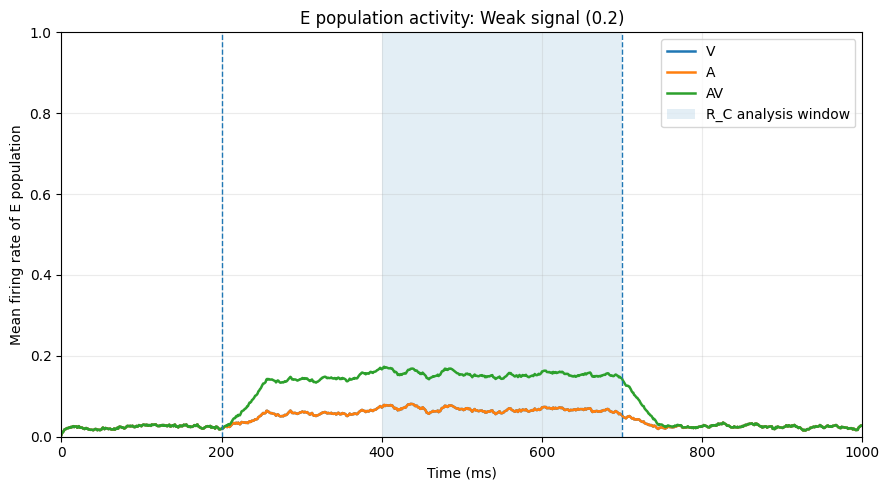

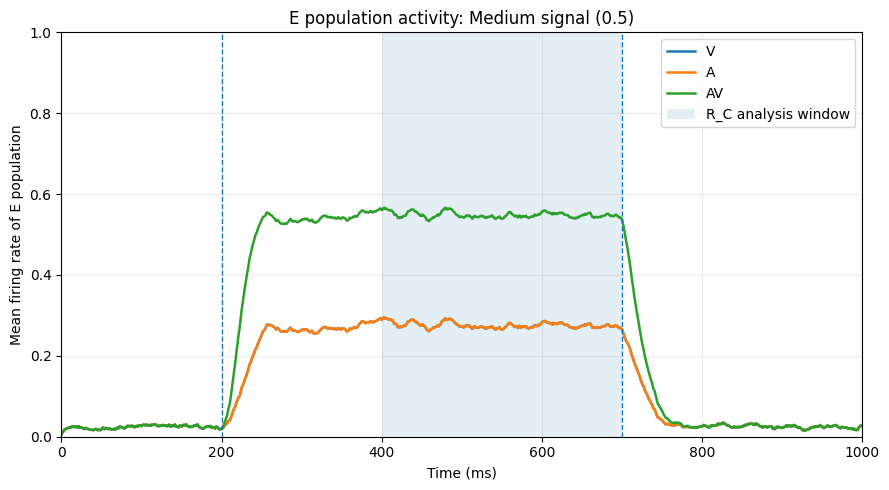

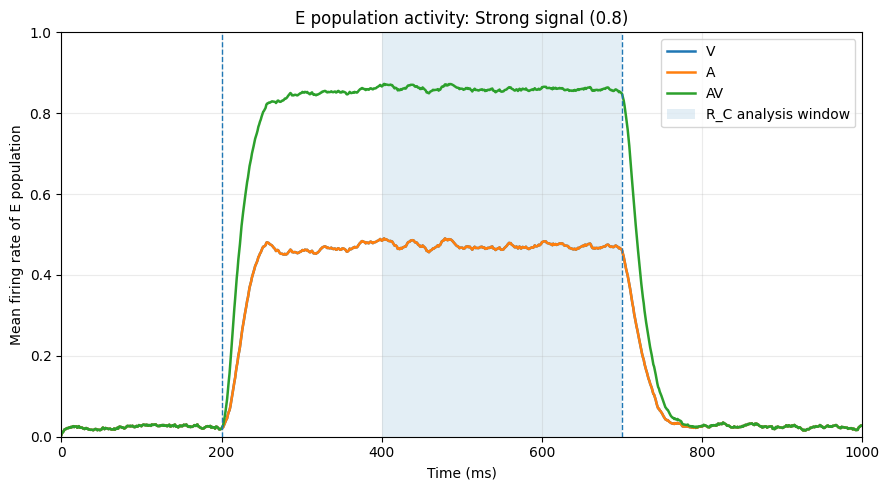

说明：由于 w_VE = w_AE 且V、A条件使用相同噪声序列，V与A曲线会完全重合。


In [8]:
strength_name_en = {
    "弱": "Weak",
    "中": "Medium",
    "强": "Strong",
}

for strength_label, strength_value in signal_strengths.items():
    fig, ax = plt.subplots(figsize=(9, 5))

    for condition in conditions:
        result = results[(strength_label, condition)]
        ax.plot(
            result["time"],
            result["E"],
            label=condition,
            linewidth=1.8
        )

    ax.axvline(T_ON, linestyle="--", linewidth=1)
    ax.axvline(T_OFF, linestyle="--", linewidth=1)
    ax.axvspan(
        ANALYSIS_START,
        ANALYSIS_END,
        alpha=0.12,
        label="R_C analysis window"
    )

    strength_en = strength_name_en[strength_label]
    ax.set_title(
        f"E population activity: {strength_en} signal ({strength_value})"
    )
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Mean firing rate of E population")
    ax.set_xlim(0, T_TOTAL)
    ax.set_ylim(0, r_max)
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()

    filename = OUTPUT_DIR / f"E_timecourse_{strength_en.lower()}.png"
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

print(
    "说明：由于 w_VE = w_AE 且V、A条件使用相同噪声序列，"
    "V与A曲线会完全重合。"
)

## 9. 信号强度—群体反应曲线

该图汇总九个条件的 \(R_C\)，用于比较：

1. 群体反应是否随信号强度增加；
2. AV条件是否高于V和A；
3. 强信号下是否出现反应饱和。

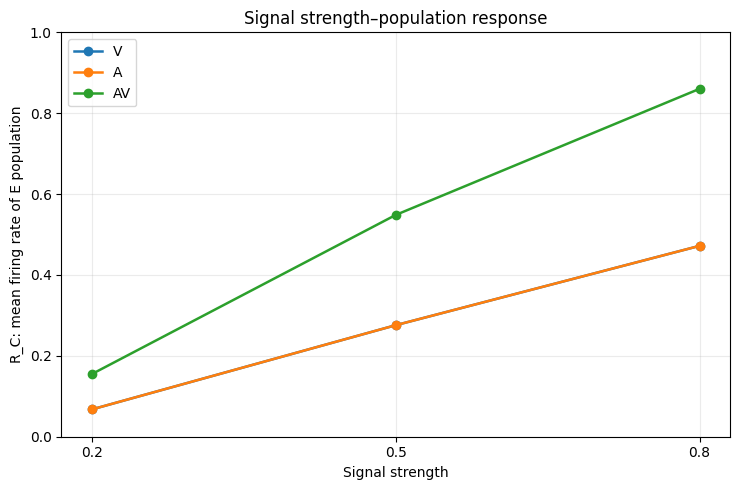

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))

for condition in conditions:
    condition_data = result_table[
        result_table["感觉条件"] == condition
    ].sort_values("输入值")

    ax.plot(
        condition_data["输入值"],
        condition_data["R_C（E群体）"],
        marker="o",
        linewidth=1.8,
        label=condition
    )

ax.set_title("Signal strength–population response")
ax.set_xlabel("Signal strength")
ax.set_ylabel("R_C: mean firing rate of E population")
ax.set_xticks(list(signal_strengths.values()))
ax.set_ylim(0, r_max)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "signal_strength_response.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 10. E-I活动辅助诊断

以下结果不是主要多感官指标，但可确认抑制群体是否随兴奋活动增强。

- \(D^+\)：E群体接收的感觉输入与回返兴奋之和
- \(D^-\)：E群体接收的反馈抑制
- 平衡指数：

\[
BI=\frac{|D^+-D^-|}{D^++D^-}.
\]

本模型是受E-I平衡理论启发的简化率模型，因此BI不要求严格等于0。

In [10]:
diagnostic_rows = []

for strength_label, strength_value in signal_strengths.items():
    for condition in conditions:
        result = results[(strength_label, condition)]
        diagnostic_rows.append({
            "信号强度": strength_label,
            "感觉条件": condition,
            "E群体反应 R_C": result["R_C"],
            "I群体反应 R_I": result["R_I"],
            "平均兴奋驱动 D+": result["D_plus"],
            "平均抑制反馈 D-": result["D_minus"],
            "平衡指数 BI": result["balance_index"],
        })

diagnostic_table = pd.DataFrame(diagnostic_rows)
diagnostic_table["信号强度"] = diagnostic_table["信号强度"].astype(strength_order)
diagnostic_table["感觉条件"] = diagnostic_table["感觉条件"].astype(condition_order)
diagnostic_table = diagnostic_table.sort_values(
    ["信号强度", "感觉条件"]
).reset_index(drop=True)

display(diagnostic_table.round(4))

diagnostic_table.to_csv(
    OUTPUT_DIR / "EI_diagnostics.csv",
    index=False,
    encoding="utf-8-sig"
)

,信号强度,感觉条件,E群体反应 R_C,I群体反应 R_I,平均兴奋驱动 D+,平均抑制反馈 D-,平衡指数 BI
0,弱,V,0.0675,0.0390,0.1680,0.0584,0.4841
1,弱,A,0.0675,0.0390,0.1680,0.0584,0.4841
2,弱,AV,0.1549,0.0798,0.3479,0.1197,0.4881
3,中,V,0.2758,0.1621,0.5979,0.2432,0.4217
4,中,A,0.2758,0.1621,0.5979,0.2432,0.4217
5,中,AV,0.5484,0.3956,1.1938,0.5934,0.3360
6,强,V,0.4720,0.3258,1.0204,0.4887,0.3523
7,强,A,0.4720,0.3258,1.0204,0.4887,0.3523
8,强,AV,0.8604,0.6708,1.9906,1.0061,0.3285


## 11. 自动生成可用于结果部分的简要文字

以下文本只根据当前一次模拟的结果生成。最终论文中应结合图表进行解释，并避免将单次模拟结果推广为统计学结论。

In [11]:
def value_from_table(table, strength, condition, column):
    row = table[
        (table["信号强度"] == strength)
        & (table["感觉条件"] == condition)
    ]
    return float(row.iloc[0][column])


print("【单次模拟结果摘要】")

for strength_label in ["弱", "中", "强"]:
    R_V = value_from_table(
        result_table, strength_label, "V", "R_C（E群体）"
    )
    R_A = value_from_table(
        result_table, strength_label, "A", "R_C（E群体）"
    )
    R_AV = value_from_table(
        result_table, strength_label, "AV", "R_C（E群体）"
    )
    MEI = float(
        mei_table.loc[
            mei_table["信号强度"] == strength_label,
            "MEI（%）"
        ].iloc[0]
    )

    print(
        f"{strength_label}信号："
        f"R_V={R_V:.4f}，"
        f"R_A={R_A:.4f}，"
        f"R_AV={R_AV:.4f}，"
        f"MEI={MEI:.2f}%。"
    )

weak_mei = float(
    mei_table.loc[mei_table["信号强度"] == "弱", "MEI（%）"].iloc[0]
)
medium_mei = float(
    mei_table.loc[mei_table["信号强度"] == "中", "MEI（%）"].iloc[0]
)
strong_mei = float(
    mei_table.loc[mei_table["信号强度"] == "强", "MEI（%）"].iloc[0]
)

if weak_mei > medium_mei > strong_mei:
    print(
        "\n本次模拟中，MEI随信号强度增加而下降，"
        "表现出与逆效应原则一致的趋势。"
    )
else:
    print(
        "\n本次模拟中，AV反应高于最佳单通道反应，"
        "但MEI未呈严格单调下降。"
    )

print(
    "\n注意：上述结论来自固定参数和固定随机种子下的单次探索性模拟，"
    "不构成统计推断。"
)

【单次模拟结果摘要】
弱信号：R_V=0.0675，R_A=0.0675，R_AV=0.1549，MEI=129.49%。
中信号：R_V=0.2758，R_A=0.2758，R_AV=0.5484，MEI=98.86%。
强信号：R_V=0.4720，R_A=0.4720，R_AV=0.8604，MEI=82.29%。

本次模拟中，MEI随信号强度增加而下降，表现出与逆效应原则一致的趋势。

注意：上述结论来自固定参数和固定随机种子下的单次探索性模拟，不构成统计推断。


## 12. 输出文件

运行Notebook后，`model_outputs` 文件夹中将包含：

- `RC_results.csv`
- `MEI_results.csv`
- `EI_diagnostics.csv`
- 三张E群体时间活动图
- 一张信号强度—群体反应图

修改参数后，应从“固定噪声”单元格开始重新运行其后的全部单元格。正式报告中应记录最终使用的完整参数。